# 실습 1. 표 데이터 AI(Kumo)로 질병 진행 예측하기

**이 실습에서 할 일**
- 당뇨병 환자 442명의 기초 검사값으로 **1년 뒤 질병 진행 점수**를 예측합니다.
- 전통적인 방법(선형회귀)과 표 데이터 파운데이션 모델 **Kumo**를 같은 조건에서 비교합니다.

**Kumo는 어떻게 예측하나요?**
Kumo는 우리 자료로 새로 학습(훈련)하지 않습니다. 정답을 아는 환자들을 **예시**로 보여 주면, 예시 속 규칙을 스스로 찾아 새 환자를 예측합니다.

| 단계 | 내용 | 시간 |
|---|---|---|
| ① | 도구 설치 | 1분 |
| ② | 데이터 보기 (내 데이터로 바꿀 수 있음) | 2분 |
| ③ | 두 모델로 예측 | 1분 |
| ④ | 결과 보기 | 3분 |
| ⑤ | 설정을 바꿔 다시 해 보기 | 3분 |

**진행 방법**
- 위에서부터 셀 왼쪽의 ▶ 버튼(또는 `Ctrl+Enter`)을 눌러 **순서대로** 실행하세요. 코드는 몰라도 됩니다.
- ⚙️ 표시가 있는 셀에서만 설정을 바꿉니다. 설정을 바꾸면 그 셀부터 아래로 다시 실행하세요.
- 처음 실행할 때 "이 노트는 Google에서 작성하지 않았습니다"라는 경고가 나오면 **[무시하고 계속하기]**를 누르세요.
- 설치 후 "런타임을 다시 시작하라"는 안내가 나오더라도 이 실습에서는 다시 시작하지 않아도 됩니다.

In [1]:
#@title ① 준비: 필요한 도구 설치 (수정본)
import warnings; warnings.filterwarnings("ignore")
import logging; logging.disable(logging.WARNING)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import koreanize_matplotlib  # 그래프에 한글 글꼴을 적용합니다
# pip install -q structured-data-models koreanize-matplotlib
# pip install -q koreanize-matplotlib

from IPython.display import display, Markdown, HTML
pd.set_option("display.precision", 2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("✅ 준비 완료 | 계산 장치:", "GPU" if DEVICE.type == "cuda" else "CPU")

# if DEVICE.type != "cuda":
    # print("   CPU로도 실행됩니다. 더 빠르게 하려면 메뉴 [런타임] → [런타임 유형 변경] → [T4 GPU]를 고르세요.")

✅ 준비 완료 | 계산 장치: CPU


In [2]:
if DEVICE.type != "cuda":
    print("   CPU로도 실행됩니다. 더 빠르게 하려면 메뉴 [런타임] → [런타임 유형 변경] → [T4 GPU]를 고르세요.")

   CPU로도 실행됩니다. 더 빠르게 하려면 메뉴 [런타임] → [런타임 유형 변경] → [T4 GPU]를 고르세요.


In [ ]:
#@title 🔧 도구 함수 불러오기 (실행만 하세요)

import sdm
# sdm.models.KumoTabular는 엔비디아(NVIDIA)가 배포한 최신 인공지능 표 예측 모델(Structured Data Models)
# brew install python@3.12
# from sdm import SDM, SDMConfig
# brew install --cask sdm (Terminal)
from sklearn.metrics import mean_absolute_error
# pip install scikit-learn

In [6]:
SEED = 2026
_KUMO = None


def is_categorical(series, name):
    """문자 열과 성별(sex)은 범주형으로, 나머지 숫자 열은 연속형으로 다룹니다."""
    return name == "sex" or not pd.api.types.is_numeric_dtype(series)


def _kumo_output(x_context, y_context, x_query):
    global _KUMO
    if _KUMO is None:
        print("Kumo 모델을 내려받는 중입니다(처음 한 번만, 약 30초)...")
        _KUMO = sdm.models.KumoTabular(task="regression", size="small", device=DEVICE)
    stypes = {c: ("categorical" if is_categorical(x_context[c], c) else "numerical") for c in x_context.columns}
    context = sdm.TableTensor.from_pandas(x_context, stypes=stypes, device=DEVICE)
    target = sdm.TableTensor.from_pandas(
        pd.DataFrame({"target": np.asarray(y_context, dtype=float)}), stypes={"target": "numerical"}, device=DEVICE)
    query = sdm.TableTensor.from_pandas(x_query, stypes=stypes, device=DEVICE)
    torch.manual_seed(SEED)
    # GPU에서도 float32로 계산해 CPU 결과와 최대한 같게 합니다.
    with torch.inference_mode():
        return _KUMO(x_context=context, y_context=target, x_query=query, num_estimators=4)


def kumo_predict(x_context, y_context, x_query):
    """Kumo는 학습하지 않습니다. 예시(x_context, y_context)를 보고 새 환자(x_query)의 예측 중앙값을 냅니다."""
    out = _kumo_output(x_context, y_context, x_query)
    return out["q500"].numerical.squeeze(-1).float().cpu().numpy()


def kumo_mean(x_context, y_context, x_query):
    """예측 분포(999개 분위수)의 평균 = 조건부 평균의 근사값. 인과효과 계산에 씁니다."""
    out = _kumo_output(x_context, y_context, x_query)
    return out.numerical.float().mean(dim=-1).cpu().numpy()

from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

VARIABLE_NAMES = {"split": "구분", "age": "나이", "sex": "성별", "bmi": "체질량지수(BMI)", "bp": "평균 혈압",
                  "s1": "총콜레스테롤", "s2": "LDL", "s3": "HDL", "s4": "총콜레스테롤/HDL",
                  "s5": "중성지방(로그)", "s6": "혈당", "target": "1년 뒤 진행 점수"}
SPLIT_NAMES = {"train": "학습(예시)", "validation": "검증", "test": "시험"}


def load_example_data():
    """당뇨병 환자 442명(Efron 등, 2004; scikit-learn 내장)을 불러와 264/89/89명으로 나눕니다."""
    df = load_diabetes(as_frame=True, scaled=False).frame
    order = np.random.default_rng(SEED).permutation(len(df))
    split = np.empty(len(df), dtype=object)
    split[order[:264]], split[order[264:353]], split[order[353:]] = "train", "validation", "test"
    df.insert(0, "split", split)
    return df


def add_split(df):
    """split 열이 없으면 60% 학습 / 20% 검증 / 20% 시험으로 무작위로 나눕니다."""
    if "split" in df.columns:
        bad = set(df["split"]) - set(SPLIT_NAMES)
        if bad:
            raise ValueError(f"split 열에는 train / validation / test만 쓸 수 있습니다. 다른 값: {bad}")
        return df
    n = len(df)
    order = np.random.default_rng(SEED).permutation(n)
    split = np.empty(n, dtype=object)
    split[order[: int(n * 0.6)]] = "train"
    split[order[int(n * 0.6): int(n * 0.8)]] = "validation"
    split[order[int(n * 0.8):]] = "test"
    return df.assign(split=split)


def load_my_data(path, target, features):
    df = pd.read_csv(path)
    if target not in df.columns:
        raise ValueError(f"목표 열 '{target}'이(가) 없습니다. CSV에 있는 열: {list(df.columns)}")
    if not pd.api.types.is_numeric_dtype(df[target]):
        raise ValueError(f"목표 열 '{target}'은(는) 숫자여야 합니다.")
    df = df.dropna(subset=[target]).reset_index(drop=True)
    cols = [c.strip() for c in features.split(",") if c.strip()] or [c for c in df.columns if c not in (target, "split")]
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f"CSV에 없는 열 이름입니다: {missing}")
    df = add_split(df)
    return df[["split"] + cols + [target]].rename(columns={target: "target"}), cols


def fit_ridge(x_train, y_train, x_query):
    """전통적 방법: 빈칸은 중앙값으로 채우고, 문자 열은 0/1로 바꾼 뒤 선형회귀(Ridge)를 학습합니다."""
    text = [c for c in x_train.columns if not pd.api.types.is_numeric_dtype(x_train[c])]
    num = [c for c in x_train.columns if c not in text]
    parts = [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num)]
    if text:
        parts.append(("text", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                            OneHotEncoder(handle_unknown="ignore")), text))
    model = make_pipeline(ColumnTransformer(parts), Ridge(alpha=1.0)).fit(x_train, y_train)
    return model.predict(x_query)


def explain(maes):
    (name_a, a), (name_b, b) = maes.items()
    gap = abs(a - b)
    if gap < 0.5:
        verdict = "두 모델의 차이가 거의 없습니다."
    else:
        winner = name_a if a < b else name_b
        verdict = f"**{winner}**의 오차가 {gap:.1f}점({gap / max(a, b) * 100:.0f}%) 더 작습니다."
    display(Markdown(f"**해석**: 환자 한 명당 평균 오차는 {name_a} **{a:.1f}점**, {name_b} **{b:.1f}점**입니다. {verdict}"))


def plot_observed_vs_predicted(y_true, predictions, title):
    y_true = np.asarray(y_true)
    fig, axes = plt.subplots(1, len(predictions), figsize=(5.2 * len(predictions), 4.4), sharex=True, sharey=True)
    lo = min(y_true.min(), *(p.min() for p in predictions.values()))
    hi = max(y_true.max(), *(p.max() for p in predictions.values()))
    for ax, (name, pred) in zip(np.atleast_1d(axes), predictions.items()):
        ax.scatter(y_true, pred, alpha=0.7, s=26)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="완벽한 예측선")
        ax.set(title=f"{name}\n평균 절대 오차(MAE) = {mean_absolute_error(y_true, pred):.1f}",
               xlabel="실제 값", ylabel="예측 값")
        ax.legend(loc="upper left")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

print("✅ 도구 함수 준비 완료")

✅ 도구 함수 준비 완료


## ② 데이터 보기

기본 예제는 **당뇨병 환자 442명**의 실제 자료입니다(Efron 등, 2004).
- 입력: 나이, 성별, BMI, 평균 혈압, 혈청 검사 6가지 (총콜레스테롤, LDL, HDL, 총콜레스테롤/HDL, 중성지방, 혈당)
- 목표: 1년 뒤 질병 진행 점수 (25~346, 클수록 많이 진행)

환자를 세 묶음으로 나눕니다.
- **학습(예시) 264명**: 모델에게 보여 주는 예시
- **검증 89명**: 두 모델을 비교하는 데 씁니다
- **시험 89명**: 마지막 확인용으로 남겨 둡니다(실습 4에서 사용)

> **내 데이터로 해 보기**: 왼쪽 📁(파일) 창에 CSV를 끌어다 놓고, 아래 셀에서 `USE_MY_DATA`를 체크한 뒤 파일 이름과 열 이름을 적으세요. 한 행이 한 사람이고, 예측할 **숫자** 열이 하나 있으면 됩니다. 빈칸과 문자 열도 쓸 수 있습니다.

In [7]:
#@title ⚙️ ② 데이터 고르기
#@markdown **기본 예제**를 쓰려면 그대로 실행하세요.
USE_MY_DATA = False  #@param {type:"boolean"}
#@markdown ---
#@markdown **내 데이터를 쓸 때만** 채우세요.
MY_CSV_FILE = "my_data.csv"  #@param {type:"string"}
#@markdown 예측하려는 숫자 열 이름
TARGET_COLUMN = "target"  #@param {type:"string"}
#@markdown 입력으로 쓸 열 이름(쉼표로 구분). 비워 두면 목표 열을 뺀 모든 열을 씁니다.
FEATURE_COLUMNS = ""  #@param {type:"string"}
#@markdown `split` 열(train / validation / test)이 있으면 그대로 쓰고, 없으면 60% / 20% / 20%로 나눕니다.

if USE_MY_DATA:
    data, ALL_FEATURES = load_my_data(MY_CSV_FILE, TARGET_COLUMN, FEATURE_COLUMNS)
    print(f"내 데이터: {len(data)}명, 입력 변수 {len(ALL_FEATURES)}개")
else:
    data = load_example_data()
    ALL_FEATURES = ["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
    print("기본 예제: 당뇨병 환자 442명, 기초 검사 변수 10개")
print("나누기:", " / ".join(f"{SPLIT_NAMES[s]} {(data['split'] == s).sum()}명" for s in SPLIT_NAMES))
display(data.head().assign(split=lambda d: d["split"].map(SPLIT_NAMES)).rename(columns=VARIABLE_NAMES))

기본 예제: 당뇨병 환자 442명, 기초 검사 변수 10개
나누기: 학습(예시) 264명 / 검증 89명 / 시험 89명


,구분,나이,성별,체질량지수(BMI),평균 혈압,총콜레스테롤,LDL,HDL,총콜레스테롤/HDL,중성지방(로그),혈당,1년 뒤 진행 점수
0,검증,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.86,87.0,151.0
1,검증,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.89,69.0,75.0
2,학습(예시),72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.67,85.0,141.0
3,학습(예시),24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.89,89.0,206.0
4,시험,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.29,80.0,135.0


## ③ 두 모델로 예측하기

- **선형회귀(Ridge)**: 각 변수에 가중치를 곱해 더하는 전통적 방법입니다. 학습 자료로 가중치를 학습합니다.
- **Kumo(표 데이터 AI)**: 학습 자료 264명을 *예시*로 보여 주기만 합니다. 모델 자체는 바뀌지 않습니다.

두 모델 모두 **검증 환자 89명**의 점수를 예측합니다. 정답은 예측이 끝난 뒤 비교할 때만 씁니다.

In [9]:
#@title ⚙️ ③ 사용할 변수 고르기 (기본 예제에서만 적용)
FEATURE_SET = "전체 10개 변수"  #@param ["전체 10개 변수", "BMI 하나만"]

In [10]:
# ③ 예측 실행
features = ["bmi"] if (FEATURE_SET == "BMI 하나만" and not USE_MY_DATA) else ALL_FEATURES
train = data[data["split"] == "train"]
valid = data[data["split"] == "validation"]

predictions = {
    "선형회귀": fit_ridge(train[features], train["target"], valid[features]),
    "Kumo": kumo_predict(train[features], train["target"], valid[features]),
}
print("✅ 예측 완료 | 사용한 변수:", ", ".join(VARIABLE_NAMES.get(c, c) for c in features))

Kumo 모델을 내려받는 중입니다(처음 한 번만, 약 30초)...
✅ 예측 완료 | 사용한 변수: 나이, 성별, 체질량지수(BMI), 평균 혈압, 총콜레스테롤, LDL, HDL, 총콜레스테롤/HDL, 중성지방(로그), 혈당


## ④ 결과 보기

**평균 절대 오차(MAE)** = 실제 점수와 예측 점수 차이의 평균입니다. **작을수록 정확**합니다.
그림에서 점이 점선(완벽한 예측선)에 가까울수록 잘 맞힌 것입니다.

,모델,평균 절대 오차(MAE)
0,선형회귀,49.00
1,Kumo,46.08


**해석**: 환자 한 명당 평균 오차는 선형회귀 **49.0점**, Kumo **46.1점**입니다. **Kumo**의 오차가 2.9점(6%) 더 작습니다.

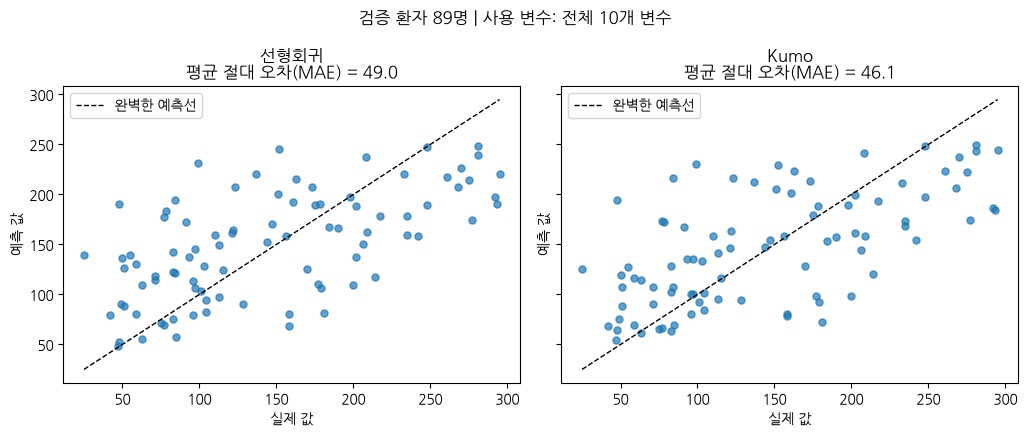

In [11]:
# ④ 결과 표와 그림
maes = {name: mean_absolute_error(valid["target"], pred) for name, pred in predictions.items()}
display(pd.DataFrame({"모델": list(maes), "평균 절대 오차(MAE)": list(maes.values())}).round(2))
explain(maes)
plot_observed_vs_predicted(valid["target"], predictions, f"검증 환자 {len(valid)}명 | 사용 변수: {FEATURE_SET if not USE_MY_DATA else '내 데이터'}")

## ⑤ 바꿔 보기

1. ⚙️ ③ 셀에서 `FEATURE_SET`을 **"BMI 하나만"**으로 바꾸고, ③부터 다시 실행하세요.
2. 두 모델의 오차가 어떻게 변했나요? Kumo의 장점이 그대로 유지되나요?

> **생각해 볼 점**
> - 변수가 충분할 때 Kumo는 학습 없이도 선형회귀보다 정확했습니다. 변수 사이의 복잡한 관계를 예시에서 찾아내기 때문입니다.
> - 정보가 BMI 하나뿐이면 어떤 모델도 크게 나아지지 않습니다. AI도 **자료에 없는 정보를 만들어 내지는 못합니다.**
> - 이 결과는 환자 89명, 자료 하나에서 얻은 것입니다. 일반적인 우열로 확대 해석하지 않습니다.